## US Visa Prediction Project

Life cycle of machine learning project
- Understanding the problem statement
- Data Collection
- Exploratory data analysis
- Data Cleaning
- Data Pre-processing 
- model Training
- choose best model

## About

The Immigration and Nationality Act(INA) of the US permits foreign workers to come to the United states to work on either a temporary or permanent basis. the act also protects US workers against adverse impacts on working place and maintain requirements when they hire foreign workers to fill workforce shortages. the immigration programs are administered by the Office of foreign Labor Certification (OFLC).

 1.Problem statement
 - OFLC gives job certification applications for employers seeking to bring foreign workers into the United states and grants certifications
 - As in last year the count of employess were huge so OFLC needs Machine
 learning models to shortlist visa applicats based on their previous data. in this project we are going to use the data given to build a classification model:
 - This model is to check if Visa get approved or not based on the given dataset.
 - This can be used to recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the certain criteria which influences the decision.

 2. Data Collection.
 - The dataset is part of Office of foreign labor certifications (OFLC) the data consists of 25480 Rows and 12 Columns
 https://www.kaggle.com/datasets/moro23/easyvisa-dataset


2.1 Import data and required packages importing pandas, Numpy, matplotlib, seaborn and warning library

In [2]:
print("hello")


hello


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

warnings.filterwarnings("ignore")

%matplotlib inline

In [4]:
df = pd.read_csv(r"EasyVisa.csv")

In [5]:
df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [6]:
df.shape

(25480, 12)

In [7]:
df.describe()

,no_of_employees,yr_of_estab,prevailing_wage
count,25480.000000,25480.000000,25480.000000
mean,5667.043210,1979.409929,74455.814592
std,22877.928848,42.366929,52815.942327
min,-26.000000,1800.000000,2.136700
25%,1022.000000,1976.000000,34015.480000
50%,2109.000000,1997.000000,70308.210000
75%,3504.000000,2005.000000,107735.512500
max,602069.000000,2016.000000,319210.270000


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


## Exploring data

In [8]:
# define numerical and categorical coumns
numeric_features = [feature for feature in df.columns if df[feature].dtype != 'O']
categorical_features = [feature for feature in df.columns if df[feature].dtype == 'O']

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features),numeric_features))
print('We have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 3 numerical features : ['no_of_employees', 'yr_of_estab', 'prevailing_wage']
We have 9 categorical features : ['case_id', 'continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'region_of_employment', 'unit_of_wage', 'full_time_position', 'case_status']


In [10]:
# Proportion of count data on categorical columns
for col in categorical_features:
    print(df[col].value_counts(normalize=True)*100)
    print('------------------------------')

case_id
EZYV01       0.003925
EZYV16995    0.003925
EZYV16993    0.003925
EZYV16992    0.003925
EZYV16991    0.003925
               ...   
EZYV8492     0.003925
EZYV8491     0.003925
EZYV8490     0.003925
EZYV8489     0.003925
EZYV25480    0.003925
Name: proportion, Length: 25480, dtype: float64
------------------------------
continent
Asia             66.173469
Europe           14.646782
North America    12.919937
South America     3.343799
Africa            2.162480
Oceania           0.753532
Name: proportion, dtype: float64
------------------------------
education_of_employee
Bachelor's     40.164835
Master's       37.810047
High School    13.422292
Doctorate       8.602826
Name: proportion, dtype: float64
------------------------------
has_job_experience
Y    58.092622
N    41.907378
Name: proportion, dtype: float64
------------------------------
requires_job_training
N    88.402669
Y    11.597331
Name: proportion, dtype: float64
------------------------------
region_of_employment

## Insights

- case_id have unique values for each column which can be dropped as it , here there is no importance
- continent column is highly biased towards asia. hence we can combine other categories to form a single category.
- unit_of_wages seems to be an important column as most of them are yearly contracts.



## Univariate Analysis 
- The term univariate analysis refers to the analysis of one variable prefix "uni" means "one". the purpose of univariate analysis is to understand the distribution of values for a single variable. Other Type of analysis are:
- Bivariate Analysis: The analysis of two variables
- Multivariate Analysis: The analysis of two or more variables

## Numerical Features

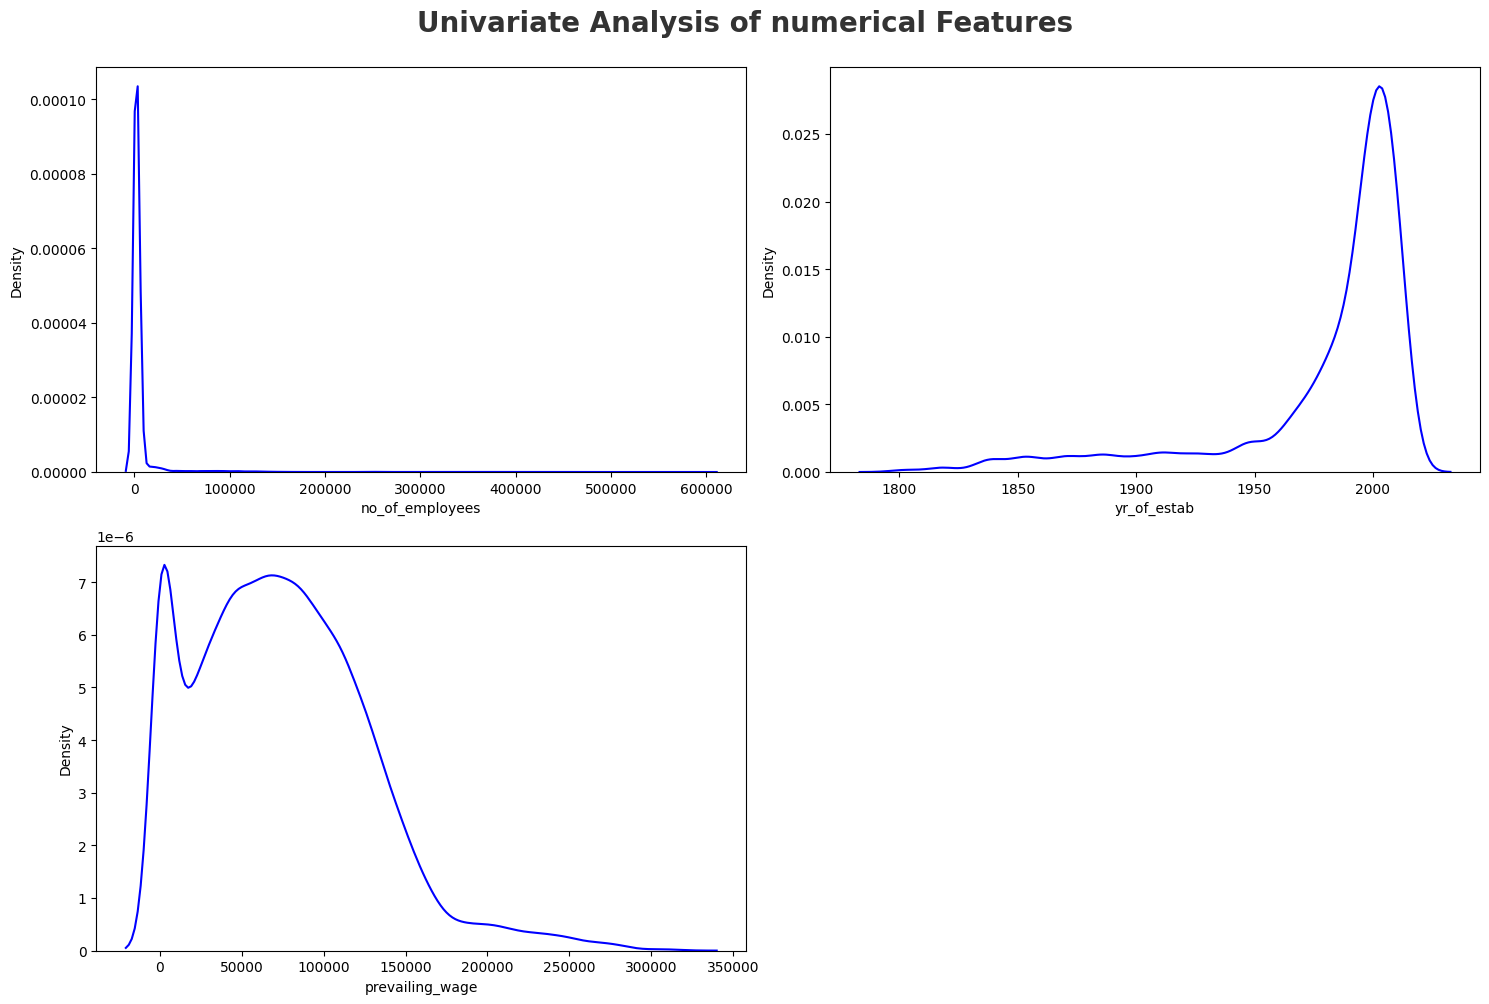

In [9]:
plt.figure(figsize=(15,10))
plt.suptitle("Univariate Analysis of numerical Features", fontsize=20,fontweight='bold',alpha=0.8,y=1.)

for i in range(0, len(numeric_features)):
    plt.subplot(2,2, i+1)
    sns.kdeplot(x=df[numeric_features[i]], color='blue')
    plt.xlabel(numeric_features[i])
plt.tight_layout()

In [11]:
import math

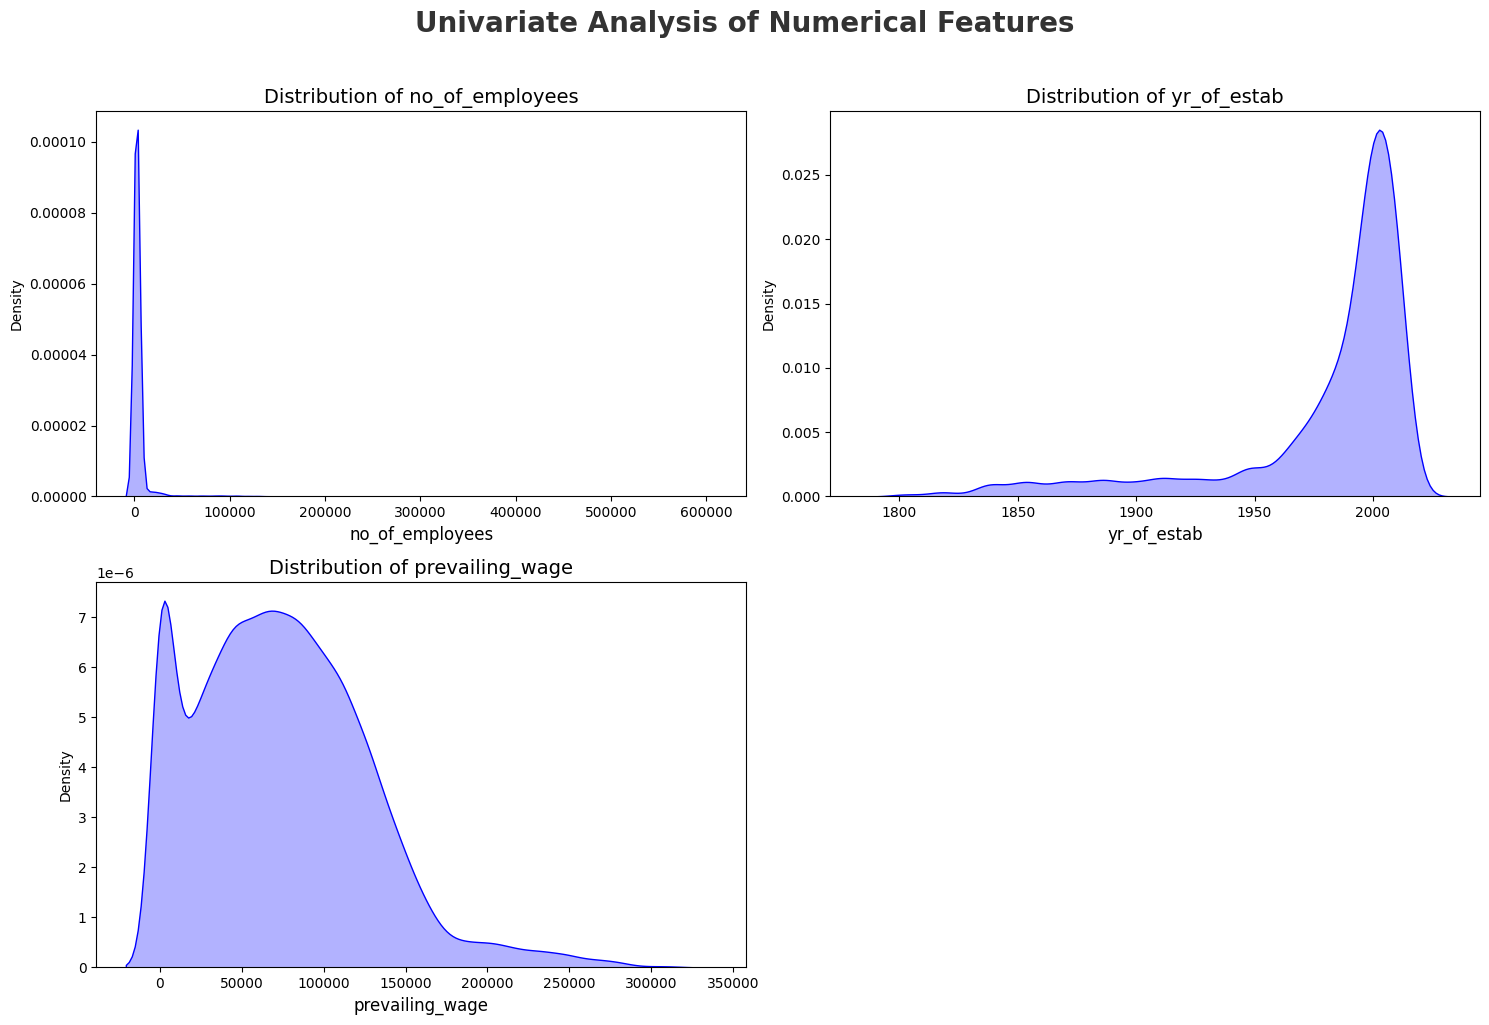

In [12]:
# Dynamically calculate rows and columns (2 columns layout)
n_features = len(numeric_features)
n_cols = 2
n_rows = math.ceil(n_features / n_cols)

plt.figure(figsize=(15, 5 * n_rows))
plt.suptitle("Univariate Analysis of Numerical Features", fontsize=20, fontweight='bold', alpha=0.8, y=1.02)

for i in range(n_features):
    plt.subplot(n_rows, n_cols, i + 1)
    
    # added fill=True for a cleaner density visualization
    sns.kdeplot(x=df[numeric_features[i]], color='blue', fill=True, alpha=0.3)
    
    plt.xlabel(numeric_features[i], fontsize=12)
    plt.title(f"Distribution of {numeric_features[i]}", fontsize=14)

# Call tight_layout once outside the loop at the end
plt.tight_layout()
plt.show()

## Insights
- no of employees column looks more skewed but it may be because of outliers
- Yr_of_estab is a discrete feature.
- privailing-wage is a right-skewed distribution


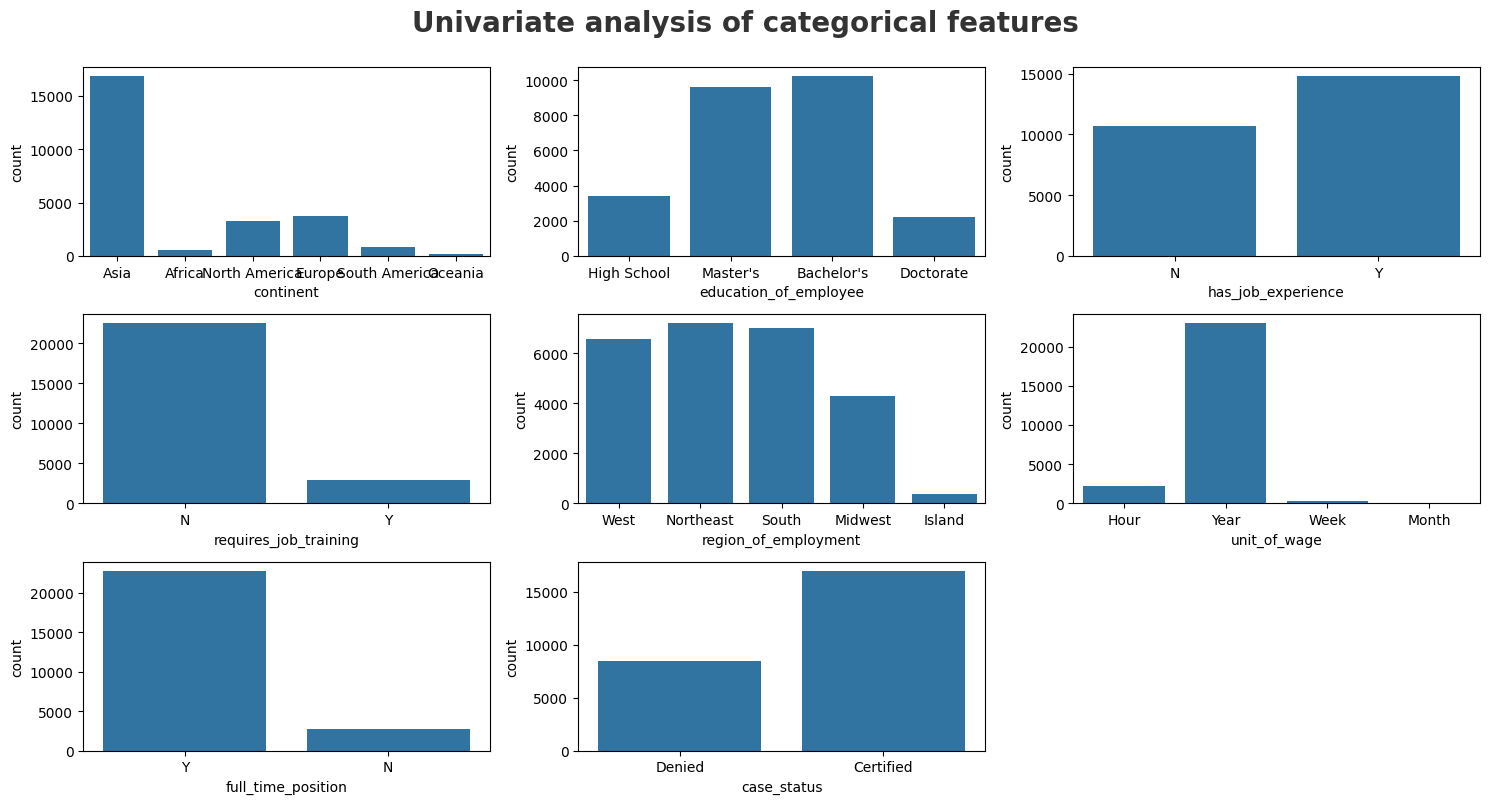

In [13]:
# Categorical columns
categorical_features.remove('case_id')
plt.figure(figsize=(15,8))
plt.suptitle("Univariate analysis of categorical features", fontsize=20, fontweight='bold', alpha=0.8,y=1.)

for i in range(0, len(categorical_features)):
    plt.subplot(3,3, i+1)
    sns.countplot(x=df[categorical_features[i]])
    plt.xlabel(categorical_features[i])

plt.tight_layout()

## Insights
- requires_job_training, unit_of_wage, full_time_position and continents columns have single category dominating
- In rest of the columns are balanced

## Multivariate Analysis
- multivariate analysis is the analysis of more than one variable

In [14]:
discrete_features = [feature for feature in numeric_features if len(df[feature].unique()) <= 25]
continuous_features = [feature for feature in numeric_features if len(df[feature].unique()) > 25]

print('We have {} discrete features: {}'.format(len(discrete_features),discrete_features))
print('We have {} continuous features: {}'.format(len(continuous_features),continuous_features))

We have 0 discrete features: []
We have 3 continuous features: ['no_of_employees', 'yr_of_estab', 'prevailing_wage']


In [15]:
df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


## Insights
- There is no multicollinearity between any variables

## Check Multicollinearity for categorical features
- A chi-squared test(also chi-square or x^2 test) is a statistical hypothesis test that is valid to perform when the test is chi-squared distributed under the null hypothesis, specially pearson's chi-squared test
- A chi-square statistic is one way to show a realtionship between two categorical variables.
- here we test correlation of categorical columns with target column i.e
case_status

NUll Hypothesis(): The feature is independent of target column (No-correlation)

Alternative Hypothesis (): The feature and target column are not independent (Correlated)


X^2 = summmation(observed - expected)^2/expected

In [18]:
from scipy.stats import chi2_contingency
import pandas as pd

chi2_test = []
for feature in categorical_features:
    if chi2_contingency(pd.crosstab(df['case_status'], df[feature]))[1] < 0.05:
        chi2_test.append('Relation')
    else:
        chi2_test.append('No Relation')

result = pd.DataFrame(data=[categorical_features, chi2_test]).T
result.columns = ['Column', 'Hypothesis Result']
result

,Column,Hypothesis Result
0,continent,Relation
1,education_of_employee,Relation
2,has_job_experience,Relation
3,requires_job_training,No Relation
4,region_of_employment,Relation
5,unit_of_wage,Relation
6,full_time_position,Relation
7,case_status,Relation


## Report 
- Here requires_job_training has no relation to target column

In [19]:
# Checking null values
df.isnull().sum()

case_id                  0
continent                0
education_of_employee    0
has_job_experience       0
requires_job_training    0
no_of_employees          0
yr_of_estab              0
region_of_employment     0
prevailing_wage          0
unit_of_wage             0
full_time_position       0
case_status              0
dtype: int64

In [20]:
continuous_features = [feature for feature in numeric_features if len(df[feature].unique()) >= 10]
print('Number of continues features: ', continuous_features)

Number of continues features:  ['no_of_employees', 'yr_of_estab', 'prevailing_wage']


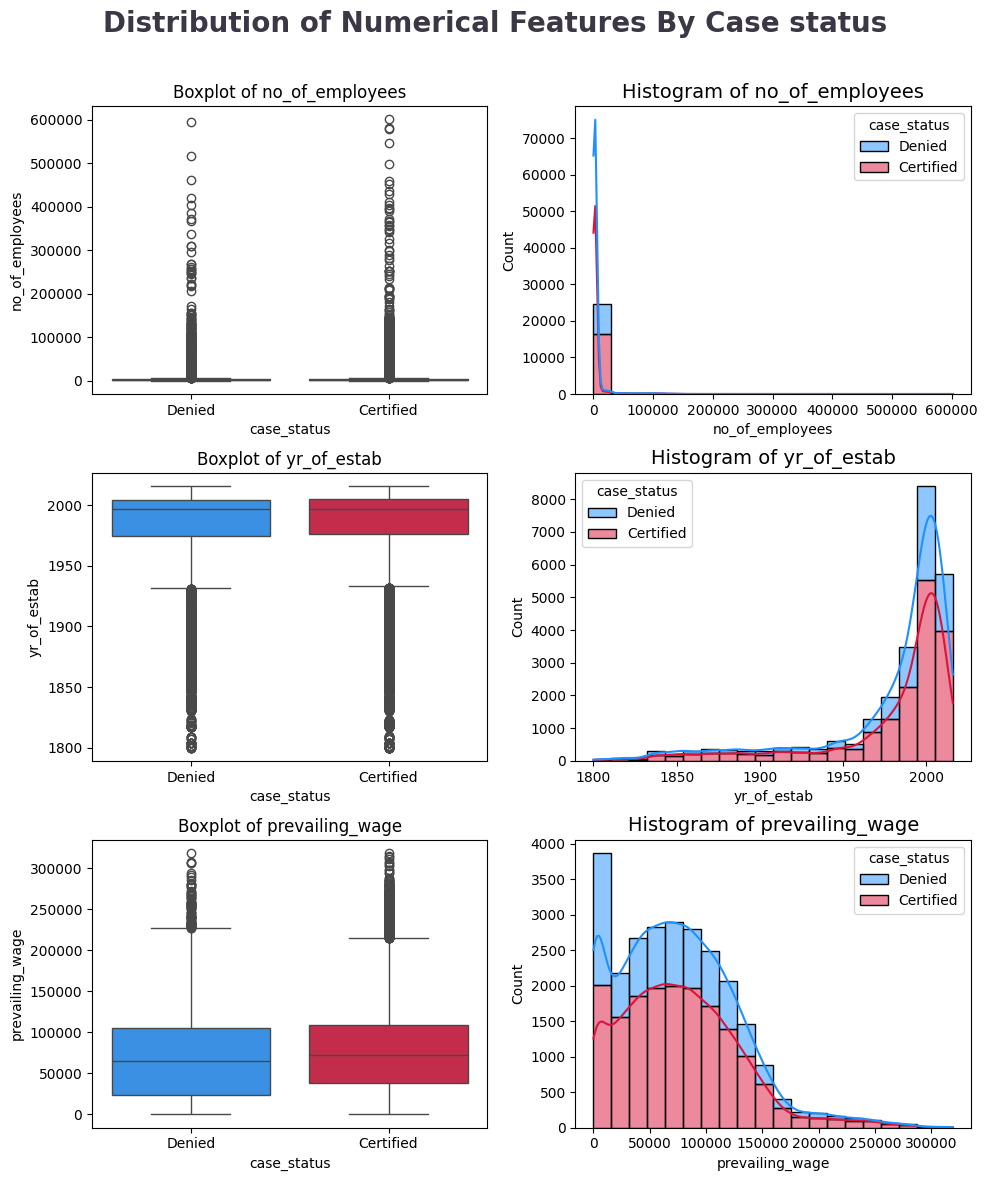

In [23]:
clr1 = ['#1E90FF', '#DC143C']
fig, ax = plt.subplots(3,2, figsize=(10,12))
fig.suptitle('Distribution of Numerical Features By Case status', color='#3C3744', fontsize=20, fontweight='bold', ha='center')

for i, col in enumerate(continuous_features):
    sns.boxplot(data=df, x='case_status', y=col, palette=clr1, ax=ax[i,0])
    ax[i,0].set_title(f'Boxplot of {col}', fontsize=12)
    sns.histplot(data=df, x=col, hue='case_status', bins=20, kde=True, multiple='stack', palette=clr1, ax=ax[i,1])
    ax[i,1].set_title(f'Histogram of {col}', fontsize=14)

fig.tight_layout()
fig.subplots_adjust(top=0.90)


## Initial Analysis Report
- No of Employees has many outliers which can be Handled in Feature Engineering and no_of_employees is Right Skewed.
- yr_of_estab is left skewed and some outliers below the lower bound of Box plot.
- prevailing_wage is right skewed with outliers above upper bound of box plot.
- There are No missing values in the dataset.
- The case_id column can be deleted because each row has unique values.
- The case_status column is the target to predict.
- In the Categorical column, features can be made Binary numerical in feature Encoding

4. Visualization
- 4.1 Visualize the target feature

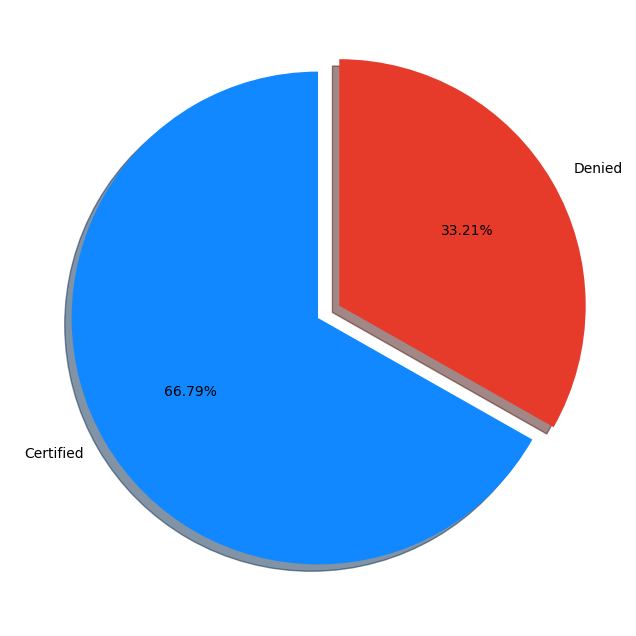

In [24]:
percentage = df.case_status.value_counts(normalize=True)*100
labels = ['Certified', 'Denied']

# plot Piechart with Ploty library
fig,ax = plt.subplots(figsize=(15,8))
explode = (0,0.1)
colors = ['#1188ff','#e63a2a']
ax.pie(percentage, labels=labels, startangle=90, autopct='%1.2f%%', explode=explode, shadow=True, colors=colors)
plt.show()

- from the chart it is seen that the target variable is imbalanced what is imbalanced data( smote ( synthetic minority oversampling techniques))

Imbalanced data : a type of data where the target class has an uneven distribution of obervation i.e here certified value has more count than the denied value of the dataset

4.2 Does applicant continent has any impact on visa status?

In [25]:
# group data by continent and their count of case_status
df.groupby('continent')['case_status'].value_counts(normalize=True).to_frame()*100

proportion
continent     case_status            
Africa        Certified     72.050817
              Denied        27.949183
Asia          Certified     65.310480
              Denied        34.689520
Europe        Certified     79.233655
              Denied        20.766345
North America Certified     61.877278
              Denied        38.122722
Oceania       Certified     63.541667
              Denied        36.458333
South America Certified     57.863850
              Denied        42.136150

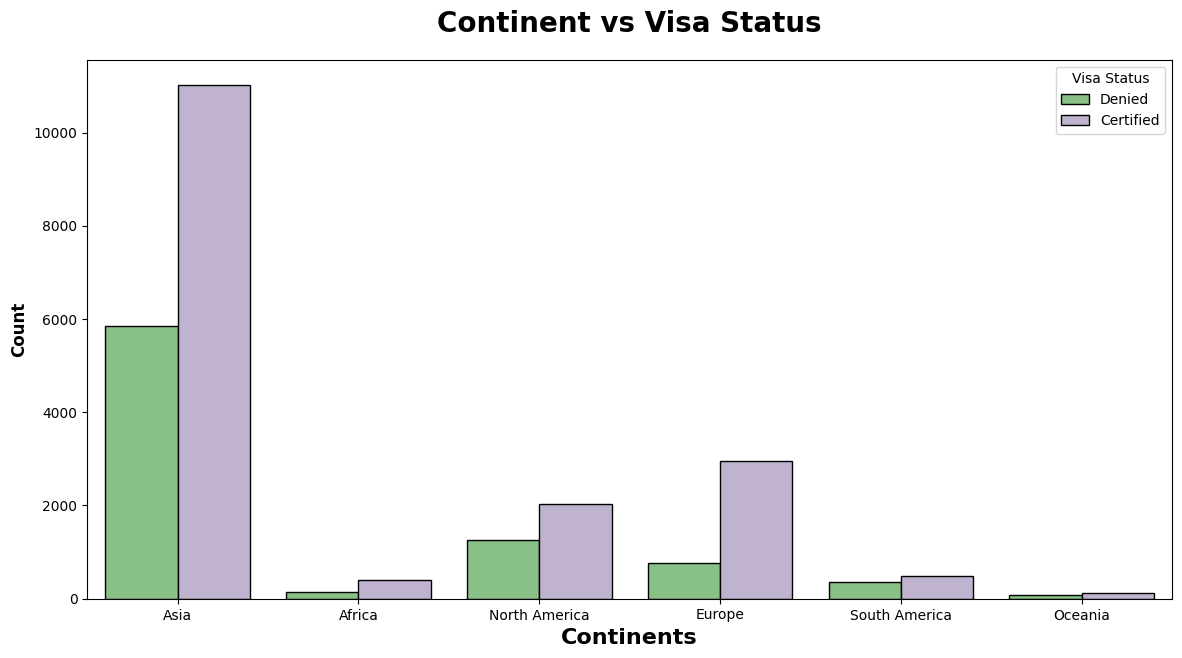

In [26]:
plt.subplots(figsize=(14,7))
sns.countplot(x="continent",hue="case_status", data=df, ec = "black",palette="Accent")
plt.title("Continent vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.xlabel("Continents", weight="bold", fontsize=16)
plt.legend(title="Visa Status", fancybox=True)
plt.show()

Does applicant education has any impact on visa status?

In [27]:
#group data by education and their count of case_status
df.groupby('education_of_employee')['case_status'].value_counts(normalize=True).to_frame()*100

proportion
education_of_employee case_status            
Bachelor's            Certified     62.214188
                      Denied        37.785812
Doctorate             Certified     87.226277
                      Denied        12.773723
High School           Denied        65.964912
                      Certified     34.035088
Master's              Certified     78.627777
                      Denied        21.372223

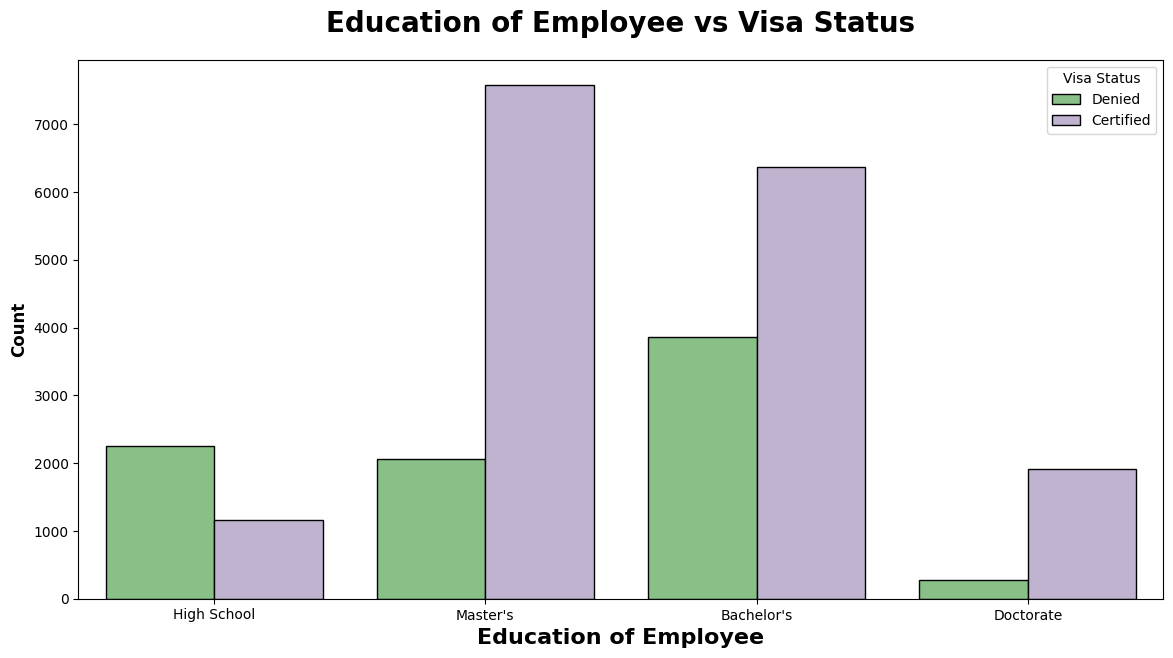

In [28]:
plt.subplots(figsize=(14,7))
sns.countplot(x="education_of_employee",hue="case_status", data=df, ec = "black",palette="Accent")
plt.title("Education of Employee vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.xlabel("Education of Employee", weight="bold", fontsize=16)
plt.legend(title="Visa Status", fancybox=True)
plt.show()

## Insights
- education status has high impact
- Doctorate and master's graduates have higher chance of getting accepted then others

In [29]:
# group data by has_job_experience and count case_status
df.groupby('has_job_experience')['case_status'].value_counts(normalize=True).to_frame()*100

proportion
has_job_experience case_status            
N                  Certified     56.134108
                   Denied        43.865892
Y                  Certified     74.476422
                   Denied        25.523578

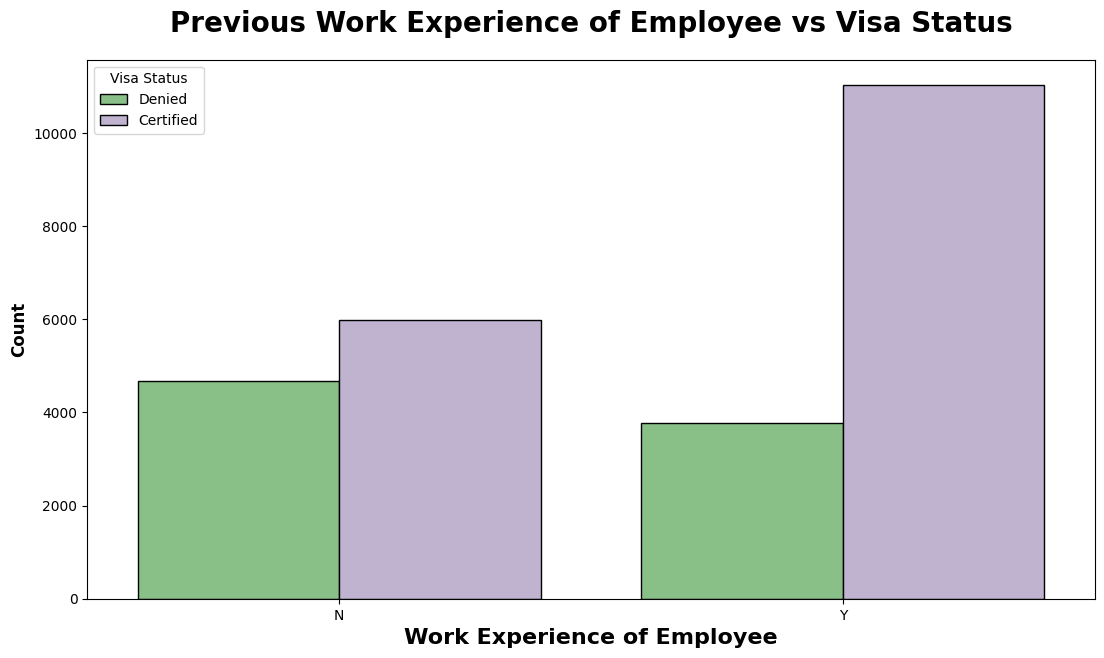

In [30]:
plt.subplots(figsize=(13,7))
sns.countplot(x="has_job_experience",hue="case_status", data=df, ec= "black",palette="Accent")
plt.title("Previous Work Experience of Employee vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.xlabel("Work Experience of Employee", weight="bold", fontsize=16)
plt.legend(title="Visa Status", fancybox=True)
plt.show()

4.6 Does number of employees of employer has nay impact on visa status


In [31]:
df.groupby('no_of_employees')['case_status'].value_counts(normalize=True).to_frame()*100

proportion
no_of_employees case_status            
-26             Certified     57.142857
                Denied        42.857143
-25             Certified     80.000000
                Denied        20.000000
-17             Certified     50.000000
...                                 ...
 547172         Certified    100.000000
 579004         Certified    100.000000
 581468         Certified    100.000000
 594472         Denied       100.000000
 602069         Certified    100.000000

[10689 rows x 1 columns]

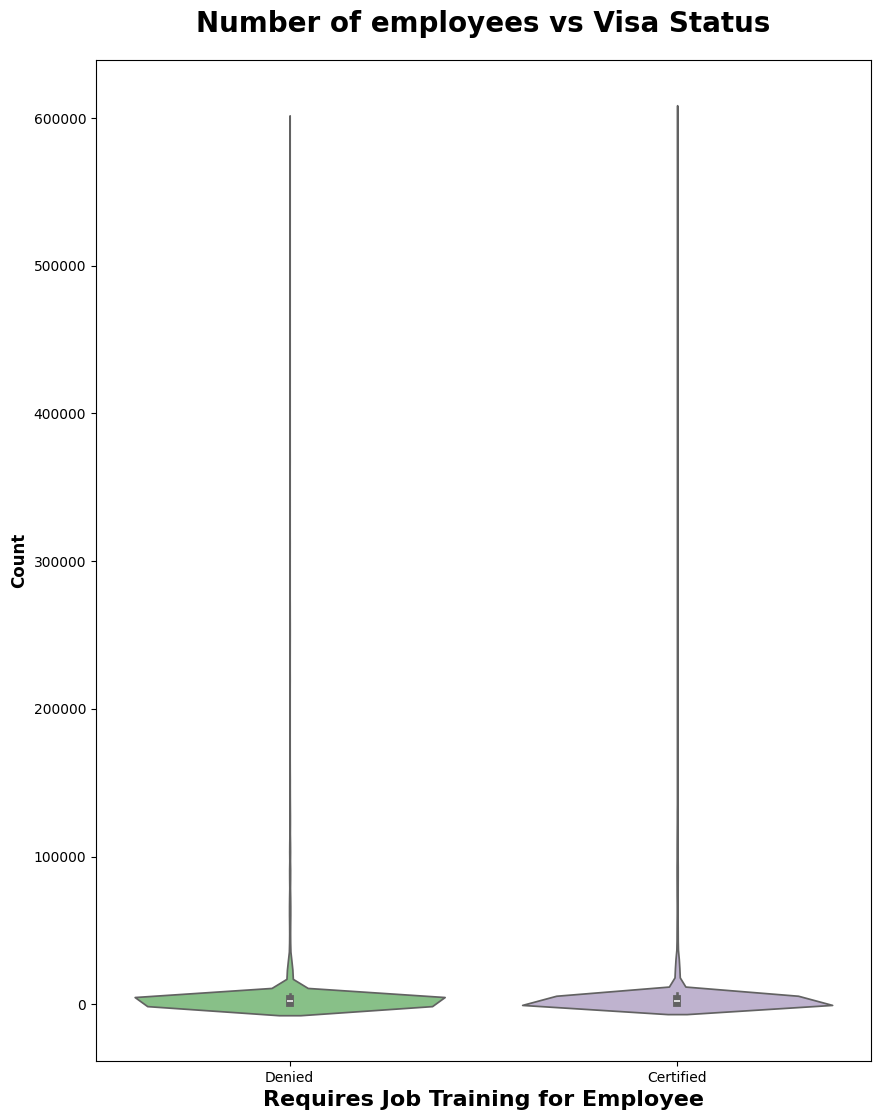

In [32]:
plt.subplots(figsize=(10,13))
sns.violinplot(x="case_status",y='no_of_employees', data=df, palette="Accent")
plt.title("Number of employees vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.xlabel("Requires Job Training for Employee", weight="bold", fontsize=16)
plt.ylim()
plt.show()

4.7 Wages and its impact on visa status


In [36]:
# group data by unit_of_wages and count the case_status
df.groupby('unit_of_wage')['case_status'].value_counts(normalize=True).to_frame()*100

proportion
unit_of_wage case_status            
Hour         Denied        65.368567
             Certified     34.631433
Month        Certified     61.797753
             Denied        38.202247
Week         Certified     62.132353
             Denied        37.867647
Year         Certified     69.885027
             Denied        30.114973

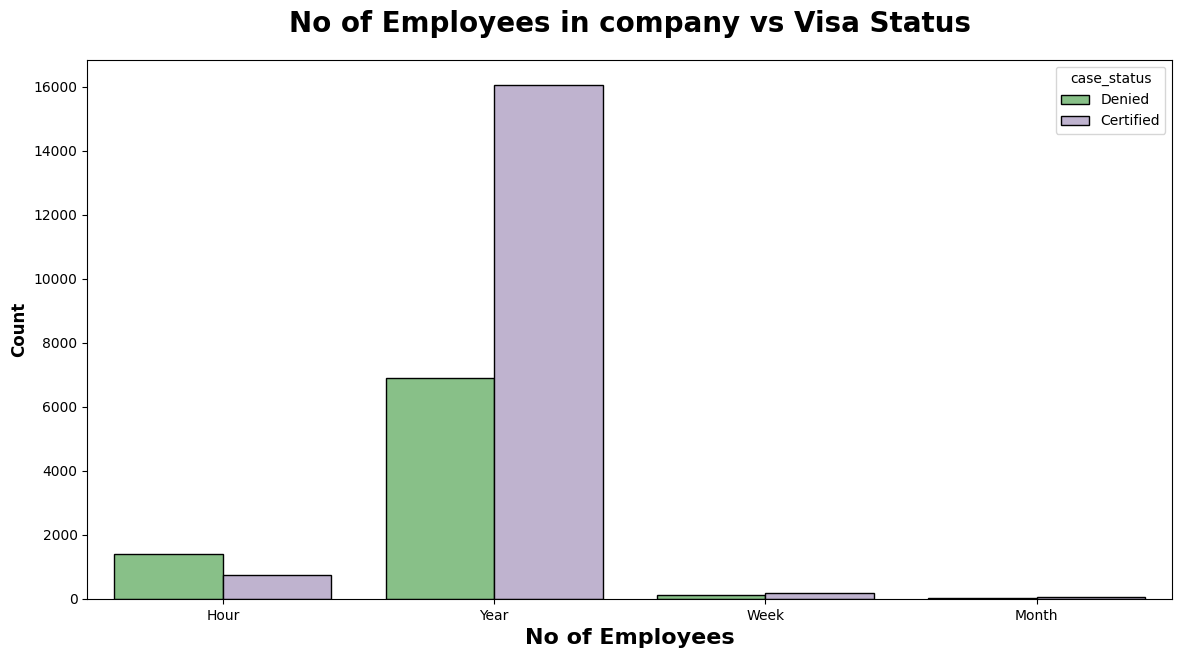

In [37]:
plt.subplots(figsize=(14,7))
sns.countplot(x="unit_of_wage",hue="case_status", data=df,ec='k', palette='Accent')
plt.title("No of Employees in company vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.xlabel("No of Employees", weight="bold", fontsize=16)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.show()


## Report

- For employees who applied for hourly pay 65% of them were denied.
- Yearly unit wage application were accepted for 69% and denied for 31% of the time.
- There is a higher chance of yearly contract than other and immediately followed by week and month

4.8 Does Region of employment has impact on visa status

In [38]:
df.groupby('region_of_employment')['case_status'].value_counts(normalize=True).to_frame()*100

proportion
region_of_employment case_status            
Island               Certified     60.266667
                     Denied        39.733333
Midwest              Certified     75.528210
                     Denied        24.471790
Northeast            Certified     62.904795
                     Denied        37.095205
South                Certified     70.015676
                     Denied        29.984324
West                 Certified     62.253265
                     Denied        37.746735

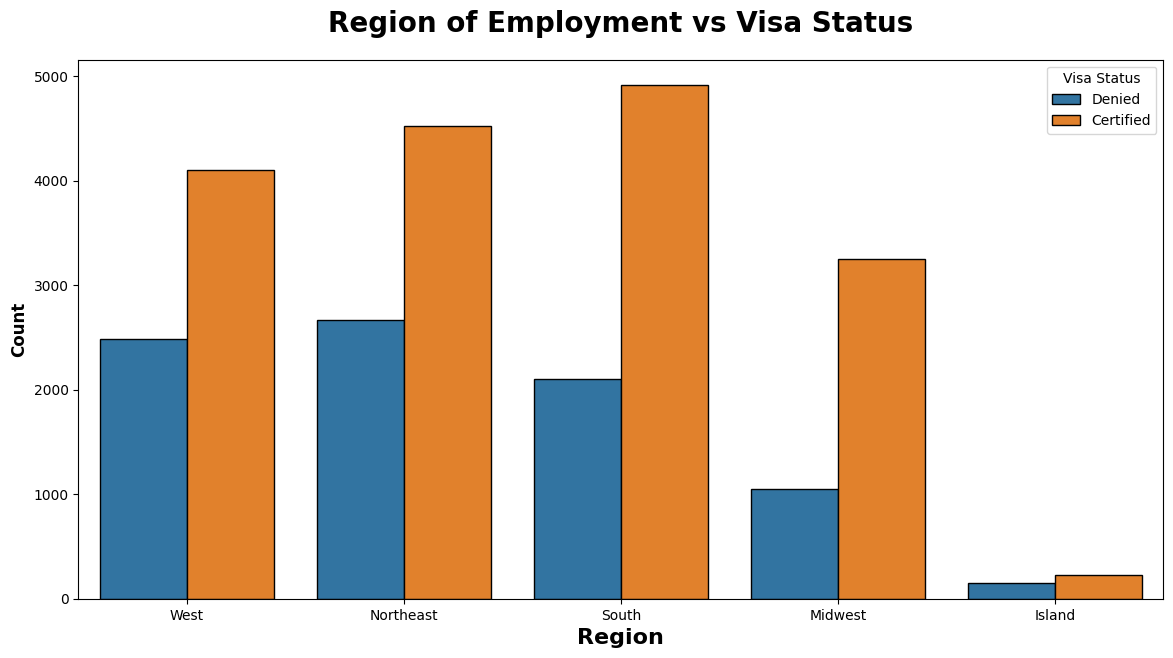

In [39]:
plt.subplots(figsize=(14,7))
sns.countplot(x="region_of_employment",hue="case_status", data=df,ec='k')
plt.title("Region of Employment vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.xlabel("Region", weight="bold", fontsize=16)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.legend(title="Visa Status", fancybox=True)
plt.show()

## Report 
- As per chart all the region have similar pattern of getting visa certified and denied
- There is a slight edge for midwest followed by south region

4.9 Does Prevailing wages has any impact on visa status ?

In [40]:
df.groupby('prevailing_wage')['case_status'].value_counts(normalize=True).to_frame()*100

,,proportion
prevailing_wage,case_status,
2.1367,Certified,100.0
2.9561,Denied,100.0
3.0031,Denied,100.0
3.3188,Denied,100.0
3.4889,Certified,100.0
...,...,...
311734.4900,Certified,100.0
314156.0600,Certified,100.0
315497.6000,Certified,100.0


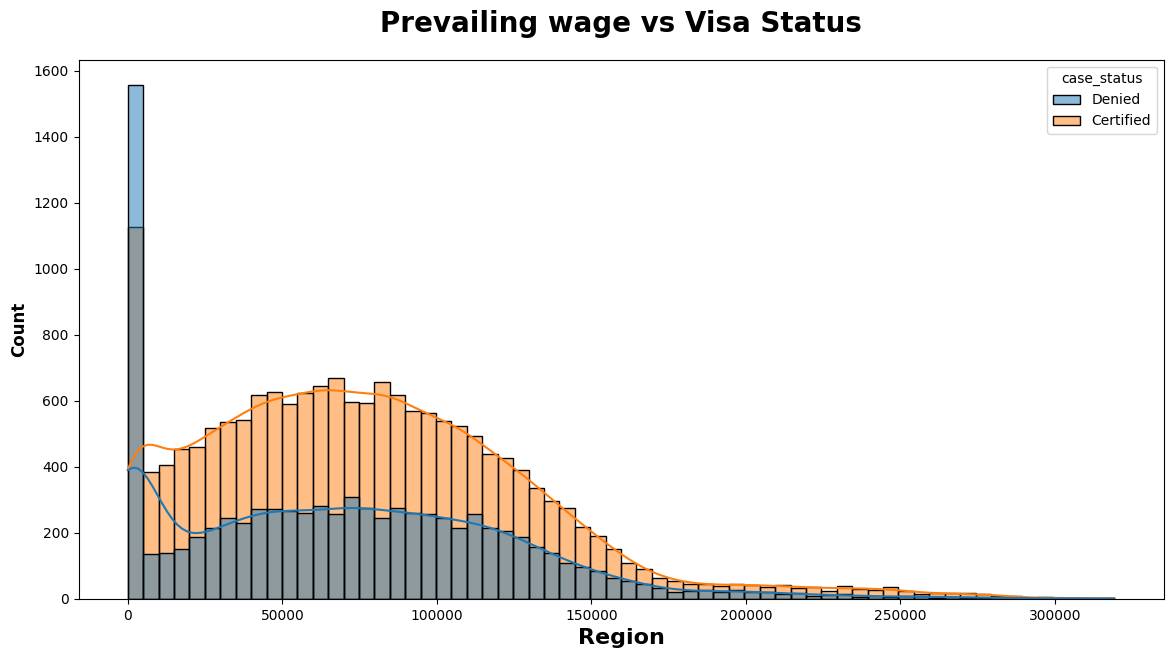

In [41]:
plt.subplots(figsize=(14,7))
sns.histplot(x="prevailing_wage",hue="case_status", data=df, kde=True)
plt.title("Prevailing wage vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.xlabel("Region", weight="bold", fontsize=16)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.show()

## Insights
- The distribution of both the classes are same but need to handle the outliers

4.9 Prevailing wage based on education

In [42]:
print('Average Prevailing wage based on employee education')
df.groupby('education_of_employee')['prevailing_wage'].mean().to_frame().sort_values(by='prevailing_wage', ascending=False)

Average Prevailing wage based on employee education


,prevailing_wage
education_of_employee,
Master's,78843.057843
Bachelor's,73405.443735
High School,71582.147756
Doctorate,64561.076657


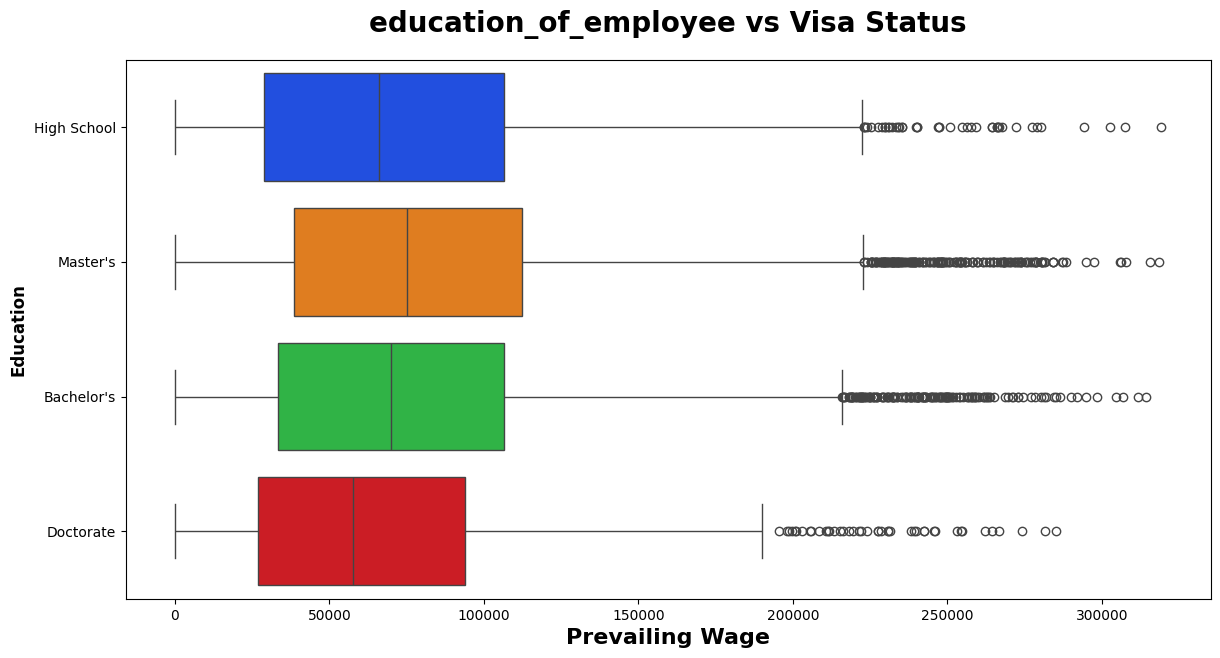

In [43]:
plt.subplots(figsize=(14,7))
sns.boxplot(y="education_of_employee",x = "prevailing_wage", data=df,palette='bright')
plt.title("education_of_employee vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.xlabel("Prevailing Wage", weight="bold", fontsize=16)
plt.ylabel("Education", weight="bold", fontsize=12)
plt.show()

4.9 yr_of_estab impact on visa_status

In [45]:
df.groupby('yr_of_estab')['case_status'].value_counts(normalize=True).to_frame()*100

proportion
yr_of_estab case_status            
1800        Certified     68.750000
            Denied        31.250000
1801        Denied        50.000000
            Certified     50.000000
1804        Certified     55.555556
...                             ...
2014        Denied        32.571429
2015        Certified     56.250000
            Denied        43.750000
2016        Certified     56.521739
            Denied        43.478261

[395 rows x 1 columns]

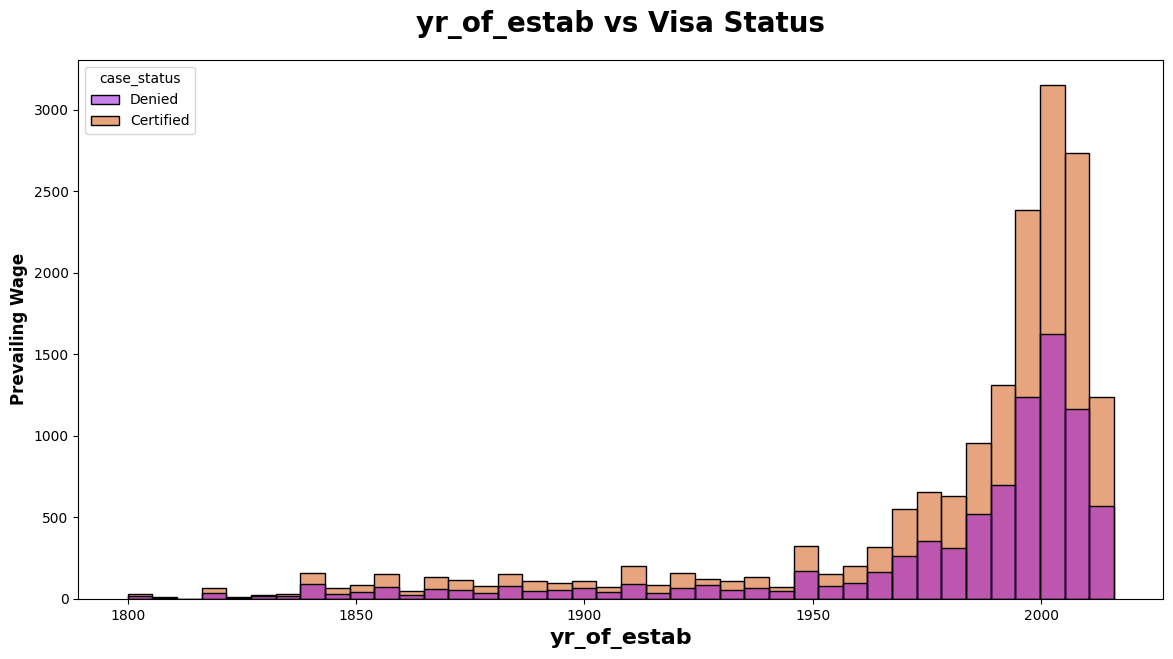

In [44]:

plt.subplots(figsize=(14,7))
sns.histplot(x = "yr_of_estab", data=df,palette='gnuplot', bins=40, hue='case_status')
plt.title("yr_of_estab vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.xlabel("yr_of_estab", weight="bold", fontsize=16)
plt.ylabel("Prevailing Wage", weight="bold", fontsize=12)
plt.show()

## Report

- Each bins consists of 5 years.
- Many companies were established after year 2000.
- The most company establishment happened in year 2000-2005.
## Final Report
- case_id column can be dropped as it is an ID.
- requires_job_training column can be dropped as it doesn't have much impact on target variable, Proved in visualization and chi2 test.
- no_of_employees, prevailing_wage columns have outllier which should be handled.
- continent columns has few unique values with very less count, which can be made as others
- Target column case_status is imbalanced can be handled before model building.